<a href="https://colab.research.google.com/github/Madz2681/beginning-bioinformatics/blob/main/Module10_Classifiers_Responder_vs_Nonresponder.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Module 10 · Classifiers: Predicting Treatment Response from Gene Expression
### Two-class sequence · Lecture 1 (models) → Lecture 2 (evaluation)

**Biological question:** *Can pretreatment gene-expression measurements predict whether a tumor will respond to therapy?*

The data labels are **Responder (0)** and **Nonresponder (1)**.

This notebook builds on our earlier supervised (regression) and unsupervised (PCA/clustering) exercises. We briefly introduce **t-SNE and UMAP** as additional unsupervised visualization methods, then compare **Logistic Regression, Support Vector Machines (SVM), and Random Forests**. Lecture 2 assesses whether those predictions generalize.

**Data:** 600 simulated tumors × 80 simulated normalized expression measurements, with measured binary treatment response and a technical batch effect. The label is a treatment *outcome*, the nonresponder class is simulated to be less common, as is typical at the drug-trial stage.

**Learning Objectives**
1. Contrast PCA, t-SNE, and UMAP; explain why an unsupervised projection does not prove biological subtypes.
2. Explain and visualize Logistic Regression, RBF SVM (`C`, `gamma`), and Random Forest.
3. Perform stratified splitting, leakage-safe Pipelines, StratifiedKFold, and GridSearchCV.
4. Interpret TN / FP / FN / TP, sensitivity (recall), specificity, precision, F1, ROC-AUC, and average precision (PR) for a named positive class.
5. Select models and thresholds without using held-out test labels; separate predictive association from causal inference.

**Assignment:** Answer each **Predict** prompt *before* the next code cell, and **Explain** using its output. Edit the **_Your response here_** text in the existing Markdown cells—**do not add new cells**. Save your executed notebook and submit the GitHub links in Canvas.

**Pacing:** Lecture 1: Sections 0–5, including t-SNE/UMAP context. Lecture 2: Sections 6–10, including validation, threshold selection, ROC and PR curves. Optional exercises follow at the end.


## 0) Setup and reproducibility
This notebook uses NumPy, pandas, matplotlib, scipy, and scikit-learn. **UMAP is optional**, because it uses a separate package. In Colab, the setup cell installs it if necessary; outside Colab, the other exercises still run if UMAP is unavailable.

In [1]:
import sys, importlib.util, subprocess
try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
if importlib.util.find_spec('umap') is None and IN_COLAB:
    print('Installing optional UMAP package in Colab (once per runtime)...')
    subprocess.check_call([sys.executable, '-m', 'pip', '-q', 'install', 'umap-learn'])

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.special import expit
from pathlib import Path
from IPython.display import display
import sklearn
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay, accuracy_score, balanced_accuracy_score,
    precision_score, recall_score, f1_score, roc_auc_score, average_precision_score,
    roc_curve, precision_recall_curve, classification_report
)

SEED = 42
BLUE, ORANGE, GREEN, PURPLE = '#0072B2', '#D55E00', '#009E73', '#CC79A7'
plt.rcParams.update({'figure.dpi':105,'font.size':11,'axes.spines.top':False,
                     'axes.spines.right':False})
OUT = Path('classifier_outputs'); OUT.mkdir(exist_ok=True)

def finish(filename):
    plt.tight_layout()
    plt.savefig(OUT / f'{filename}.png', dpi=150, bbox_inches='tight')
    plt.show()

def metrics(y_true, prediction):
    tn, fp, fn, tp = confusion_matrix(y_true, prediction, labels=[0,1]).ravel()
    return {'accuracy':accuracy_score(y_true,prediction),
            'balanced_accuracy':balanced_accuracy_score(y_true,prediction),
            'sensitivity / recall':recall_score(y_true,prediction,zero_division=0),
            'specificity':tn/(tn+fp),
            'precision':precision_score(y_true,prediction,zero_division=0),
            'F1':f1_score(y_true,prediction,zero_division=0),
            'TN':int(tn),'FP':int(fp),'FN':int(fn),'TP':int(tp)}

def show_cm(ax, truth, predictions, title):
    ConfusionMatrixDisplay.from_predictions(
        truth, predictions, labels=[0,1], display_labels=['Responder','Nonresponder'],
        cmap='Blues', colorbar=False, ax=ax, values_format='d')
    ax.set_title(title)

print('Python:',sys.version.split()[0], '| scikit-learn:',sklearn.__version__)

Python: 3.13.16 | scikit-learn: 1.6.1


## 1) Define the problem: samples, features, and labels **(Slides 1-6)**

In unsupervised learning we explored expression structure *without* known labels. Here the scientific question is supervised: given expression and **observed treatment response** for training tumors, can we predict outcomes for new tumors?

The simulated dataset has **600 tumors × 80 expression features**, with **Responder (0)** more common than **Nonresponder (1)**. A **technical batch effect** changes some expression features but is not programmed to cause the treatment outcome. Batch is not an input to the classifiers.

We split the data into **TRAIN (60%)**, **VALIDATION (20%)**, and untouched **TEST (20%)** before modeling.

* **Stratification** *preserves the response proportions in each partition.*


**Predict (before running):** What label would an always-Responder baseline assign to every tumor? Could it have reasonably high **accuracy** while detecting **zero nonresponders**? What would its statistical **sensitivity** be for the nonresponder class?

**Your response:** The always responder baseline would predict every tumor as responder (0). Since responders are more common it could still have a fairly high accuracy just by predicting the majority class. But it's statistical sensitivity for the nonresponder class would be 0%, so you would be guaranteed a chunk of false positives.


In [2]:
rng = np.random.default_rng(53)
n, p = 600, 80
program_a = rng.normal(size=n)
program_b = rng.normal(size=n)
batch = rng.integers(0,2,size=n)

# Simulated continuous normalized/log-like expression: NOT read counts.
gene_baselines = rng.normal(6.0,0.45,p)
X_all = gene_baselines + rng.normal(0, 0.95, size=(n,p))
X_all[:, 0:15] += 0.95*program_a[:,None]
X_all[:,15:30] += 0.90*program_b[:,None]
X_all[:,30:40] += 0.36*program_a[:,None] - 0.30*program_b[:,None]
X_all[:,45:70] += 2.00*batch[:,None]  # independent batch-driven expression

# Latent biology changes odds of nonresponse; neither response nor batch is a feature.
nonresponse_prob = expit(-2.25 + 1.60*program_a - 1.45*program_b
                        + 0.35*program_a*program_b)
y_all = rng.binomial(1, nonresponse_prob)
GENES = [f'Gene_{i+1:02d}' for i in range(p)]
ids = np.arange(n)

trainval_idx, test_idx = train_test_split(ids, test_size=0.20,
        stratify=y_all, random_state=SEED)
train_idx, val_idx = train_test_split(trainval_idx, test_size=0.25,
        stratify=y_all[trainval_idx], random_state=SEED)
X_train, y_train = X_all[train_idx], y_all[train_idx]
X_val, y_val = X_all[val_idx], y_all[val_idx]
X_test, y_test = X_all[test_idx], y_all[test_idx]

assert len(set(train_idx)&set(test_idx)) == 0
assert len(set(train_idx)&set(val_idx)) == 0
print('TRAIN: ',X_train.shape, '  VAL: ',X_val.shape,'  TEST (do not inspect yet): ',X_test.shape)
print('Train class proportions:',pd.Series(y_train).map({0:'Responder',1:'Nonresponder'}).value_counts(normalize=True).round(3).to_dict())
display(pd.DataFrame(X_train[:4,:6], columns=GENES[:6]).round(2))
print('Always-Responder TRAINING accuracy:',round((y_train==0).mean(),3))
print('Always-Responder sensitivity for nonresponders:',0.0)

TRAIN:  (360, 80)   VAL:  (120, 80)   TEST (do not inspect yet):  (120, 80)
Train class proportions: {'Responder': 0.778, 'Nonresponder': 0.222}


,Gene_01,Gene_02,Gene_03,Gene_04,Gene_05,Gene_06
0,7.00,5.92,6.85,5.68,5.36,7.99
1,8.30,5.95,6.42,7.85,7.61,8.18
2,8.54,4.94,6.55,5.89,4.92,5.39
3,8.23,9.01,8.60,7.00,6.23,7.62


Always-Responder TRAINING accuracy: 0.778
Always-Responder sensitivity for nonresponders: 0.0


In [3]:
### Uncomment the line below to visulaize the dataframe with features and label data stitched together. ###
#display(pd.DataFrame(X_train, columns=GENES).assign(Response=np.where(y_train == 1, "Nonresponder", "Responder"), Batch=np.asarray(batch)[train_idx]))

## 2) Beyond PCA: three ways to visualize high-dimensional samples **(Slides 7-13)**

Last week we used **PCA** to summarize expression variation. This week we add two **nonlinear** approaches, *t-distributed Stochastic Neighbor Embedding (t-SNE)* and *Uniform Manifold Approximation and Projection (UMAP)*. All three compute coordinates using **expression features**, not response labels.

| Method | What it emphasizes | What the axes / distances mean | Important settings |
|---|---|---|---|
| **PCA** | Directions of greatest overall variance; linear combinations of genes | PCs have loadings; explained variance is meaningful. | Centering and scaling; number of PCs |
| **t-SNE** | Preserving similarity among nearby samples in a low-dimensional map | Axes have no gene-specific meaning; between-island distances and island sizes can mislead. | `perplexity` (roughly the size of a typical neighborhood); random seed |
| **UMAP** | Building and laying out a graph of nearby samples, often preserving some broader structure | Axes have no biological units; spacing and apparent gaps depend on settings. | `n_neighbors` (local vs broader structure); `min_dist` (packing density); random seed |

**Important interpretation limits:** These are *visualizations*. t-SNE and UMAP can make visually compelling islands even when there is no discrete biological subtype. Different settings can change the appearance of those islands. Seeing groups is **not** a classification accuracy measurement or evidence of an underlying mechanism. Later, our classifiers fit the original **80 expression features**, **not** the two plotted coordinates.

We will fit all three on the **TRAIN** samples, after training-only scaling, and *hide the response labels initially*. UMAP requires the optional `umap-learn` library; the code will skip it outside Colab if unavailable.

**Predict (before running):** If PCA, t-SNE, or UMAP shows two islands, does that prove they are Responders and Nonresponders? Suggest one *biological* source and one *technical* source of expression structure.

**Your response:** No, seeing two islands does not prove they represent Responders and Nonresponders because the plots are made without using the response labels. A biological source of expression differences could be different tumor cell types, and a technical source could be differences in RNA quality between samples, which could affect measured gene expression levels and make samples appear more different than they actually are.


/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


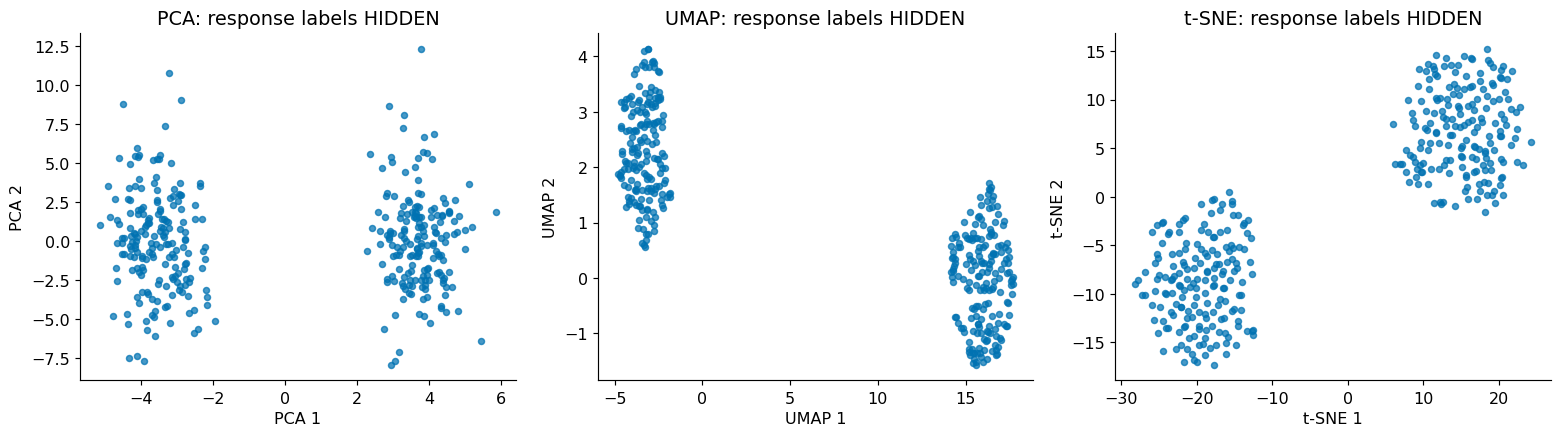

PCA variance explained by first two PCs: [0.171 0.122]


In [4]:
visual_scaler = StandardScaler().fit(X_train)  # TRAIN only
Z_train = visual_scaler.transform(X_train)
pca_vis = PCA(n_components=2, random_state=SEED).fit(Z_train)
pc_train = pca_vis.transform(Z_train)
ts_train = TSNE(n_components=2, init='pca', learning_rate='auto',
                perplexity=30, random_state=SEED).fit_transform(Z_train)
embeddings = [('PCA',pc_train), ('t-SNE',ts_train)]
try:
    import umap
    um_train = umap.UMAP(n_components=2,n_neighbors=20,min_dist=0.12,
                         random_state=SEED).fit_transform(Z_train)
    embeddings.insert(1, ('UMAP',um_train))
except ImportError:
    print('UMAP skipped outside Colab: install umap-learn if desired.')

fig,axs=plt.subplots(1,len(embeddings),figsize=(5*len(embeddings),4.3))
axs=np.atleast_1d(axs)
for ax,(name,xy) in zip(axs,embeddings):
    ax.scatter(xy[:,0],xy[:,1],s=17,color=BLUE,alpha=.72)
    ax.set(xlabel=f'{name} 1',ylabel=f'{name} 2',title=f'{name}: response labels HIDDEN')
finish('02_unlabeled_embeddings')
print('PCA variance explained by first two PCs:',np.round(pca_vis.explained_variance_ratio_,3))

**Explain (after running, still before revealing labels):** Describe one pattern that appears in the plots. Why does it remain scientifically ambiguous until we examine relevant sample metadata?

**Your response:** All three plots show two distinct clusters of tumor samples. It remains scientifically ambiguous until we examine the relevant sample metadata because we dont know what is causing this separation because the response labels are hidden. The clusters could represent biological differences or technical differences.

### 2a) Why projection settings matter: same tumors, different maps

Changing t-SNE `perplexity` changes the effective neighborhood scale; changing UMAP `n_neighbors` changes how much local vs broader structure shapes its layout. These parameters **do not change the underlying gene-expression matrix**. Notice which apparent islands, shapes, and gaps persist across settings. A change in the picture is not evidence that the tumors changed.

**Predict (before running):** When we change a projection's neighborhood setting, will the locations, gaps, and apparent clusters necessarily remain unchanged? Can you use the size of a t-SNE island to estimate the number of tumors it contains?

**Your response:** the locations, gaps, and apparent clusters will change. You cannot use the size of a t-SNE island to estimate how many tumors it contains because the size of the island does not necessarily represent the number of samples.

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


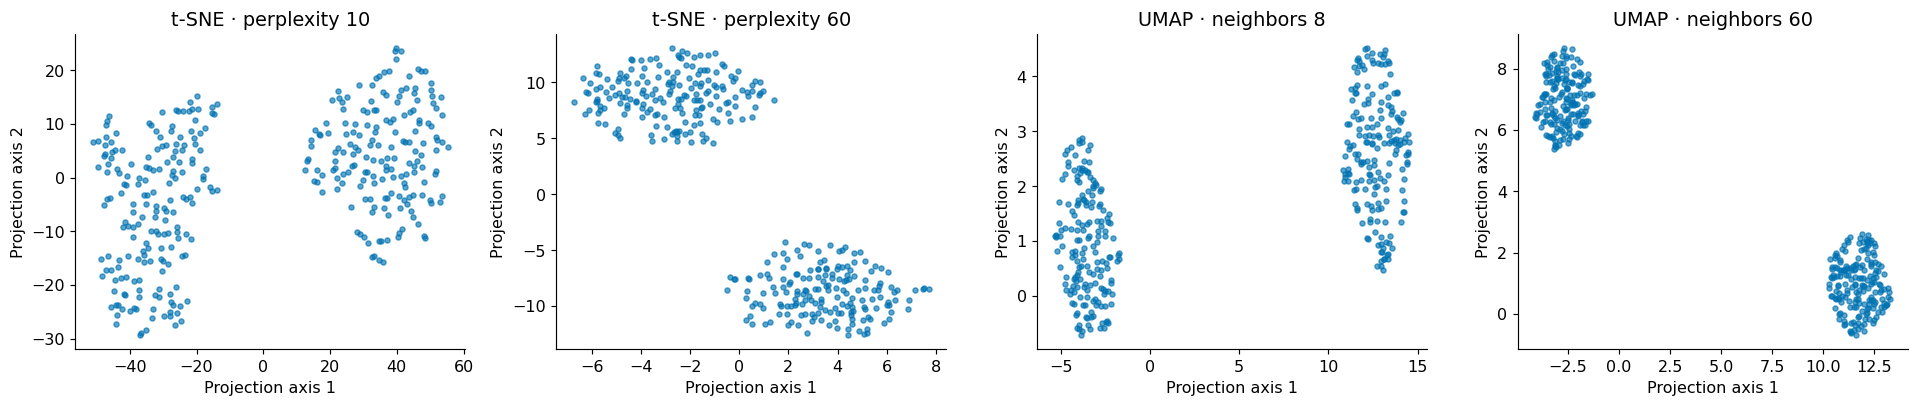

In [5]:
# Illustrate sensitivity to two neighborhood choices; TRAIN samples only.
projections=[]
for perp in (10,60):
    xy=TSNE(n_components=2,init='pca',learning_rate='auto',
            perplexity=perp,random_state=SEED).fit_transform(Z_train)
    projections.append((f't-SNE · perplexity {perp}',xy))
try:
    import umap
    for neighbors in (8,60):
        xy=umap.UMAP(n_components=2,n_neighbors=neighbors,min_dist=.12,
                     random_state=SEED).fit_transform(Z_train)
        projections.append((f'UMAP · neighbors {neighbors}',xy))
except ImportError:
    pass
fig,axs=plt.subplots(1,len(projections),figsize=(4.6*len(projections),4.0))
for ax,(name,xy) in zip(np.atleast_1d(axs),projections):
    ax.scatter(xy[:,0],xy[:,1],s=12,alpha=.64,color=BLUE)
    ax.set(title=name,xlabel='Projection axis 1',ylabel='Projection axis 2')
finish('02_projection_settings')

**Explain (after running):** Describe one change in the *appearance* of the same tumors when a projection setting changes. Why does this make it risky to interpret every plotted island as a distinct tumor subtype? What sort of independent information would help you assess the biology?

**Your response:** When you increase the amount of neighbours the cluster condense into a more tightly constrained oval. This is risky because the resulting changes mean that the islands might be caused by how the data is visualized rather than there being multiple tumor subtypes.

### 2b) Reveal response labels — then ask what actually drives structure **(Slide 14)**

Now color *the same training embeddings* by observed nonresponse status. We can also color PCA by simulated **technical batch**. This batch information is supplied **only for interpretation**; it is never used as a predictor.

**Predict:** Will every visible structure line up with the nonresponse label? If PCA separates batches more clearly than Nonresponders and Responders, is PCA necessarily wrong?

**Your response:** No, not every visible cluster will necessarily line up with treatment response because other factors, like batch effects, can influence gene expression. If PCA separates batches more clearly than Nonresponders and Responders, it doesn't mean PCA is wrong, because PCA looks for the greatest variation in the data, no matter where that variation is coming from.

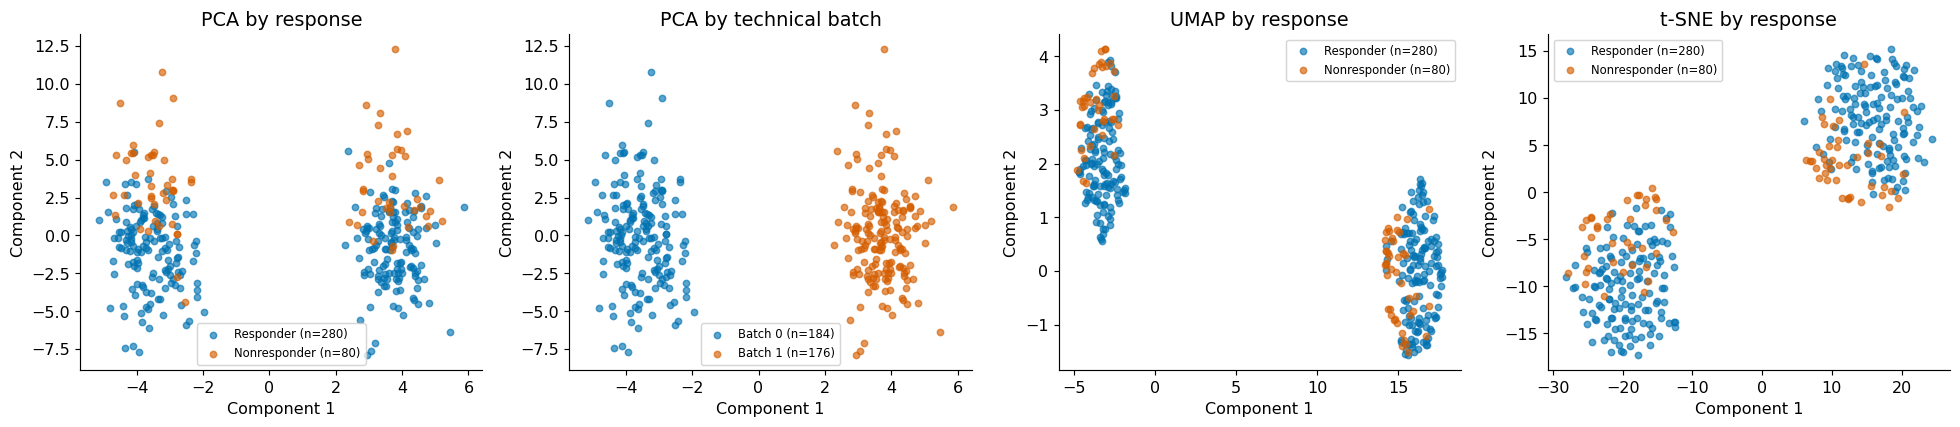

In [6]:
plots=[('PCA by response',pc_train,y_train,('Responder','Nonresponder')),
       ('PCA by technical batch',pc_train,batch[train_idx],('Batch 0','Batch 1'))]
plots += [(f'{name} by response',xy,y_train,('Responder','Nonresponder'))
          for name,xy in embeddings if name!='PCA']
fig,axs=plt.subplots(1,len(plots),figsize=(4.7*len(plots),4.2))
axs=np.atleast_1d(axs)
for ax,(title,xy,labels,names) in zip(axs,plots):
    for lab,col in [(0,BLUE),(1,ORANGE)]:
        mask=(labels==lab)
        ax.scatter(xy[mask,0],xy[mask,1],s=19,alpha=.64,color=col,label=f'{names[lab]} (n={mask.sum()})')
    ax.legend(fontsize=8)
    ax.set(xlabel='Component 1',ylabel='Component 2',title=title)
finish('02_metadata_reveal')

**Explain:** Which metadata variable appears more closely related to the main PCA structure: **response class** or **technical batch**? How does this connect to our earlier question about whether unsupervised clusters represent biologically meaningful subtypes? Can a supervised classifier still extract nonresponse-related signal that is *not* the dominant source of variance?

**Your response:** The technical batch seems more closely related to the main PCA structure because the two batches are clearly separated. This shows that unsupervised clusters dont necessarily represent meaningful biological subtypes because they could be caused by technical differences instead. A supervisied classifier can still extract nonresponse-related signal that is not the dominant source of variation because it uses the known response labels to learn diffferences that PCA might not show.

## 3) Classifier family 1: Logistic Regression **(Slides 15-18)**

Despite the name, **logistic regression is a classifier**. For a binary response, it computes a *linear score* from expression features, then converts that score to a predicted probability using the sigmoid:

$$ z = b + \sum_j w_j x_j, \qquad P(\mathrm{Nonresponder}\mid X)=\frac{1}{1+e^{-z}}. $$

A **decision threshold**, often `0.50`, converts that score into a Nonresponder (1) / Responder (0) prediction. The `C` hyperparameter is the **inverse strength of regularization**: smaller `C` means stronger regularization. Here, as in lecture, we can visualize a 2-gene model; the full predictor later uses all 80 genes.

**Predict:** If `P(nonresponse) = 0.41`, which class will be predicted with threshold `0.50`? With threshold `0.25`? If we increase `Gene_01` and its coefficient is positive, which direction does predicted probability of nonresponse move?

**Your response:** With a threshold of 0.50, the tumor would be classified as a responder (0) because 0.41 is below the threshold. With a threshold of 0.25, it would be classified as a Nonresponder. If we increase Gene_01 and its coefficient becomes positive, the predicted probability of nonresponse would increase, assuming the other genes stay the same.

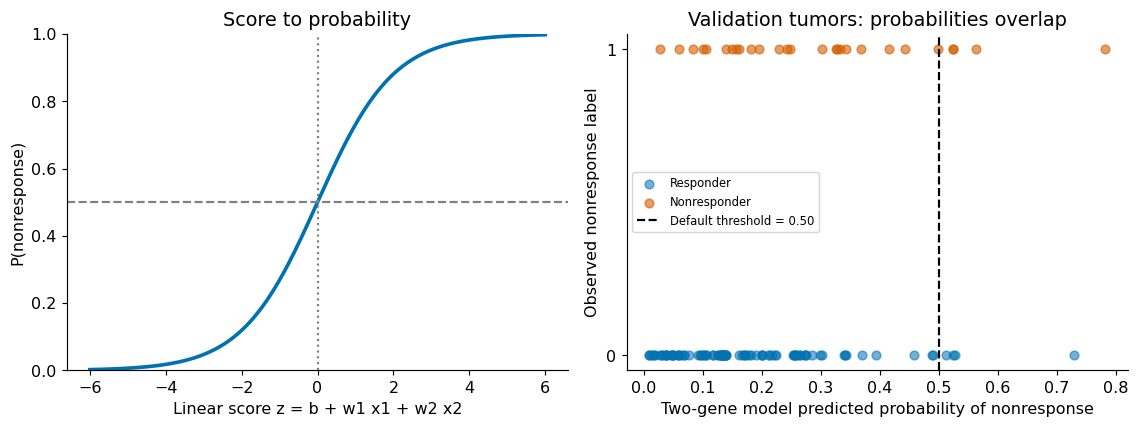

Intercept: -1.621   Standardized gene coefficients: {'Gene_01': np.float64(0.713), 'Gene_16': np.float64(-1.022)}


In [7]:
TWO = [0,15]   # Gene_01 and Gene_16 (one from each latent expression program)
X2_tr, X2_val = X_train[:,TWO], X_val[:,TWO]
logit2 = make_pipeline(StandardScaler(),LogisticRegression(C=1,max_iter=2000))
logit2.fit(X2_tr,y_train)
b=float(logit2.named_steps['logisticregression'].intercept_[0])
w=logit2.named_steps['logisticregression'].coef_[0]
z=np.linspace(-6,6,250)
fig,axs=plt.subplots(1,2,figsize=(11,4.2))
axs[0].plot(z,expit(z),color=BLUE,linewidth=2.5)
axs[0].axhline(.5,color='gray',linestyle='--'); axs[0].axvline(0,color='gray',linestyle=':')
axs[0].set(xlabel='Linear score z = b + w1 x1 + w2 x2', ylabel='P(nonresponse)',title='Score to probability',ylim=(0,1))
p2=logit2.predict_proba(X2_val)[:,1]
axs[1].scatter(p2[y_val==0],np.zeros((y_val==0).sum()),color=BLUE,alpha=.55,label='Responder')
axs[1].scatter(p2[y_val==1],np.ones((y_val==1).sum()),color=ORANGE,alpha=.60,label='Nonresponder')
axs[1].axvline(.5,color='black',ls='--',label='Default threshold = 0.50')
axs[1].set(xlabel='Two-gene model predicted probability of nonresponse',ylabel='Observed nonresponse label',yticks=[0,1],title='Validation tumors: probabilities overlap')
axs[1].legend(fontsize=8)
finish('03_logistic_probabilities')
print('Intercept:',round(b,3),'  Standardized gene coefficients:',dict(zip([GENES[j] for j in TWO],np.round(w,3))))

**Explain:** Read the fitted coefficients in the output. Which of these genes increases predicted nonresponse *odds*, holding the other fixed? Are these coefficients causal effects? Why can predicted probabilities overlap even when the classifier has learned a useful signal?

**Your response:** Gene_01 has a positive coefficient (0.713), so increasing its expression would increase the predicted offs of nonresponse while holding the other gene constant. These coeffiecients are not causal effects becuse they only show associations between gene expression and treatment response. Predicted probabilites can overlap even when the classifier has learned a useful signal because Responders and Nonresponders may have similar gene expression patterns.

# Changing the threshold does not retrain the classifier **(Slide 19)**

**Predict:** Before moving the threshold from 0.50 to 0.20, predict what will happen to sensitivity, specificity, and the number of false positives.

Your response: Sensitivity will increase, Specificity will decrease, and the number of false positives will increase.

**Explain:** Move the slider and examine the results. Why do the confusion matrix and performance metrics change even though the logistic regression model has not been retrained? Does lowering the threshold necessarily decrease precision?

Your Response: The confusion matrix and performance metrics change because moving the threshold changes which tumors are classified as Nonresponders, even though the model's predicted probabilites stay the same. Lowering the threshold does not necessarily decrease the precision but itoften does because more tumors are predicted as nonresponder, which can increase false positives.

In [8]:
import ipywidgets as widgets

# Fixed validation probabilities from the trained logistic regression
# p2 was calculated in the preceding cell.
jitter = np.random.default_rng(42).normal(0, 0.04, len(y_val))

@widgets.interact(
    threshold=widgets.FloatSlider(
        value=0.50, min=0.05, max=0.95, step=0.05,
        description="Threshold:",
        continuous_update=False
    )
)
def explore_threshold(threshold):

    # Change classifications WITHOUT retraining the model
    predictions = (p2 >= threshold).astype(int)
    m = metrics(y_val, predictions)

    fig, axs = plt.subplots(1, 2, figsize=(12, 4.5))

    # LEFT: Predicted probabilities for each tumor
    for actual, label, color in [
        (0, "Actual Responder", BLUE),
        (1, "Actual Nonresponder", ORANGE)
    ]:
        mask = y_val == actual
        axs[0].scatter(
            p2[mask], y_val[mask] + jitter[mask],
            color=color, alpha=0.65, s=35, label=label
        )

    # Highlight incorrectly classified tumors
    wrong = predictions != y_val
    axs[0].scatter(
        p2[wrong], y_val[wrong] + jitter[wrong],
        marker="x", color="black", s=65,
        label="Incorrect prediction"
    )

    # Decision threshold
    axs[0].axvline(threshold, color="black", linestyle="--",
                   linewidth=2, label=f"Threshold = {threshold:.2f}")

    axs[0].set(
        xlabel="Predicted probability of Nonresponse",
        ylabel="Actual treatment response",
        yticks=[0, 1],
        yticklabels=["Responder", "Nonresponder"],
        xlim=(0, 1),
        ylim=(-0.2, 1.2),
        title="Same probabilities, different classifications"
    )
    axs[0].legend(fontsize=8, loc="upper center")

    # RIGHT: Updated confusion matrix
    show_cm(axs[1], y_val, predictions,
            f"Confusion matrix (threshold = {threshold:.2f})")

    plt.tight_layout()
    plt.show()

    # Updated performance metrics
    display(pd.DataFrame([{
        "Accuracy": m["accuracy"],
        "Sensitivity": m["sensitivity / recall"],
        "Specificity": m["specificity"],
        "Precision": m["precision"],
        "F1": m["F1"]
    }]).round(3))

    print(f"TN={m['TN']}   FP={m['FP']}   FN={m['FN']}   TP={m['TP']}")
    print("Model coefficients and predicted probabilities are unchanged.")

interactive(children=(FloatSlider(value=0.5, continuous_update=False, description='Threshold:', max=0.95, min=…

## 4) Classifier family 2: Support Vector Machine (SVM) **(Slides 20-22)**

An **SVM** tries to separate labeled classes by a decision boundary with a large margin. A Radial Basis Function (RBF) kernel permits **nonlinear boundaries** without explicitly constructing all transformed coordinates.

The two hyperparameters emphasized in lecture are:

- **`C`**: how strongly to penalize classification errors. Small `C` = more regularization; large `C` = stronger pressure to fit training labels.
- **`gamma`**: how local a training point's influence is in the **RBF kernel**. Small `gamma` = smoother, broad influence; large `gamma` = narrower, more flexible influence.

Below we show Logistic Regression, RBF SVM, and Random Forest **using the same two genes**. These 2D diagrams explain shapes, **not** final 80-gene model selection.

**Predict:** Which family should have a *straight* decision boundary? Which can bend around individual groups? Will increasing `gamma` and `C` always improve predictions on **validation** samples?

**Your response:** Logistic Regression should have a straight decision boundary, while SVM with an RBF kernel and Random Forest can create bendy boundaries. Increasing gamma and C will not always improve validation predicitions because the model could overfit the training data and perform worse on new samples.

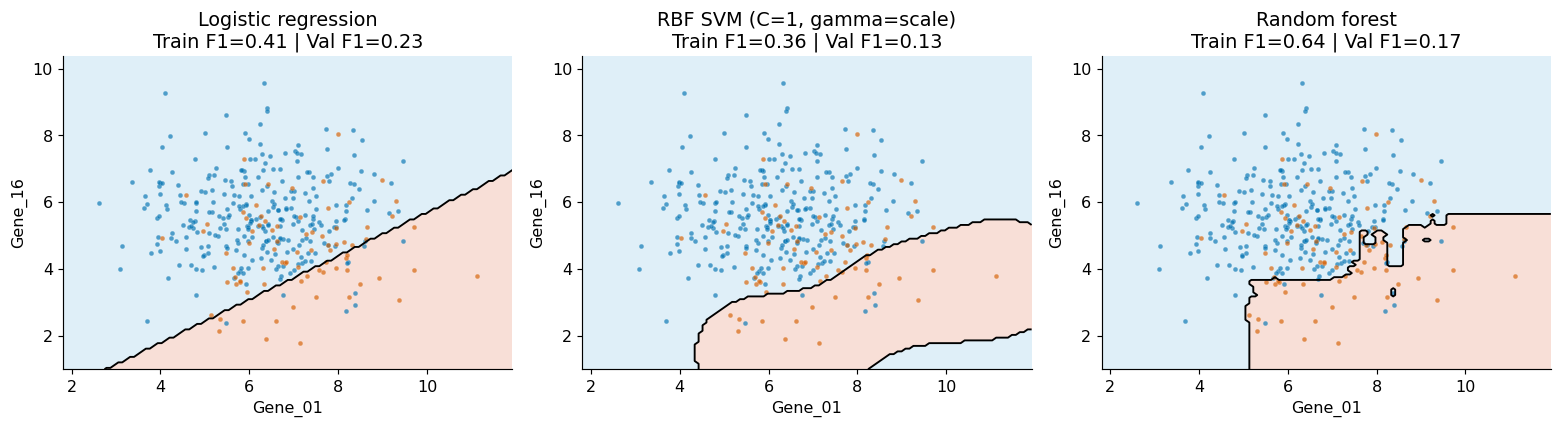

,Classifier,TRAIN F1,VALIDATION F1
0,Logistic regression,0.411,0.229
1,"RBF SVM (C=1, gamma=scale)",0.355,0.129
2,Random forest,0.641,0.167


In [9]:
from matplotlib.colors import ListedColormap

def boundary_panel(ax,model,name):
    model.fit(X2_tr,y_train)
    margin=0.8
    x1=np.linspace(X2_tr[:,0].min()-margin,X2_tr[:,0].max()+margin,115)
    x2=np.linspace(X2_tr[:,1].min()-margin,X2_tr[:,1].max()+margin,115)
    xx,yy=np.meshgrid(x1,x2)
    xy=np.c_[xx.ravel(),yy.ravel()]
    classes=model.predict(xy).reshape(xx.shape)
    ax.contourf(xx,yy,classes,levels=[-.5,.5,1.5],colors=['#D8EBF7','#F7D8CD'],alpha=.8)
    ax.contour(xx,yy,classes,levels=[.5],colors='black',linewidths=1.3)
    for cls,color in [(0,BLUE),(1,ORANGE)]:
        mask=y_train==cls
        ax.scatter(X2_tr[mask,0],X2_tr[mask,1],s=11,alpha=.65,
                   c=color,edgecolors='white',linewidths=.15)
    tr_f1=f1_score(y_train,model.predict(X2_tr),zero_division=0)
    vl_f1=f1_score(y_val,model.predict(X2_val),zero_division=0)
    ax.set(xlabel='Gene_01',ylabel='Gene_16',title=f'{name}\nTrain F1={tr_f1:.2f} | Val F1={vl_f1:.2f}')
    return tr_f1,vl_f1

boundaries={
 'Logistic regression':make_pipeline(StandardScaler(),LogisticRegression(max_iter=2000)),
 'RBF SVM (C=1, gamma=scale)':make_pipeline(StandardScaler(),SVC(kernel='rbf',C=1,gamma='scale',probability=True,random_state=SEED)),
 'Random forest':RandomForestClassifier(n_estimators=100,max_depth=6,min_samples_leaf=3,random_state=SEED,n_jobs=-1)
}
fig,axs=plt.subplots(1,3,figsize=(15,4.2))
boundary_results=[]
for ax,(name,model) in zip(axs,boundaries.items()):
    train_f1,val_f1=boundary_panel(ax,model,name)
    boundary_results.append((name,train_f1,val_f1))
finish('04_three_classifier_boundaries')
display(pd.DataFrame(boundary_results,columns=['Classifier','TRAIN F1','VALIDATION F1']).round(3))

### 4a) Experiment with `C` and `gamma`
Compare **four RBF SVM settings** with the same training/validation data. The dotted question from lecture is: *when does extra flexibility turn into overfitting?*

**Predict:** Between `C=0.1, gamma=0.03` and `C=50, gamma=5`, which is more likely to fit isolated training observations? Which will necessarily have the better validation F1?

**Your response:** The SVM with C=50 and gamma =5 is more likely to fit the isolated training observations because it has a more flexible decision boundary. Neither setting will necessarily have a better validation F1 score because the more flexible model could overfit the training data and perform worse on new samples.

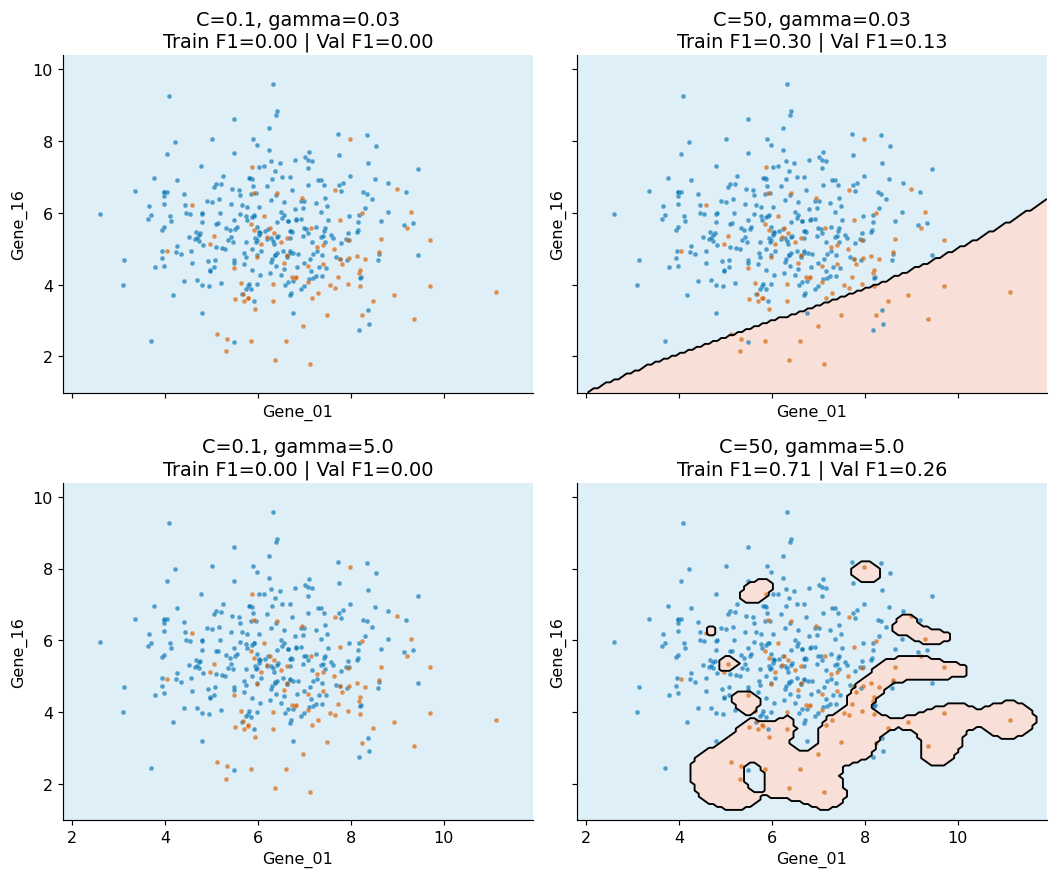

,C,gamma,TRAIN F1,VALIDATION F1
0,0.1,0.03,0.000,0.000
1,50.0,0.03,0.300,0.133
2,0.1,5.00,0.000,0.000
3,50.0,5.00,0.708,0.263


In [10]:
# C and gamma are hyperparameters supplied before training, NOT learned coefficients.
settings=[(.1,.03), (50,.03), (.1,5.0), (50,5.0)]
fig,axs=plt.subplots(2,2,figsize=(10.2,8.5),sharex=True,sharey=True)
rows=[]
for ax,(C,gamma) in zip(axs.flat,settings):
    model=make_pipeline(StandardScaler(),SVC(kernel='rbf',C=C,gamma=gamma,
                       probability=True,random_state=SEED))
    tr,vl=boundary_panel(ax,model,f'C={C}, gamma={gamma}')
    rows.append({'C':C,'gamma':gamma,'TRAIN F1':tr,'VALIDATION F1':vl})
finish('04_svm_c_gamma')
display(pd.DataFrame(rows).round(3))

**Explain:** Point to the panel with the most flexible/complex boundary. Does its training F1 look like a reliable estimate of generalization? Explain one visible instance in which allowing more complex decision boundaries helps or hurts validation performance.

**Your response:** The panel with C=50 and gamma=5 has the most complex decision boundary. Its training F1 of 0.708 is not a reliable because its validation F1 is much lower at 0.263, suggesting overfitting. However increasing the complexity from C=50, gamma=0.03, to C=50,gamma=5 improved validation f1 from 0.133 to 0.263, showing that more flexibility can help the model identify patterns, but it can also cause the model to fit the training data too closely.

## 5) Classifier family 3: Random Forest **(Slides 23-25)**

A **Random Forest** aggregates many decision trees. Each tree uses a **bootstrap sample** of the training observations and considers a random subset of features at a split. Its class probability is typically the **average class probability from the trees**, so it can also be thresholded.

The *impurity-based feature importance* scores (Gini index) indicate which features the trees used to reduce impurity, **not** proof of biological causation. Correlated expression measurements may split importance among themselves.

#### Visualize the first few layers of the first tree in the Random Forest

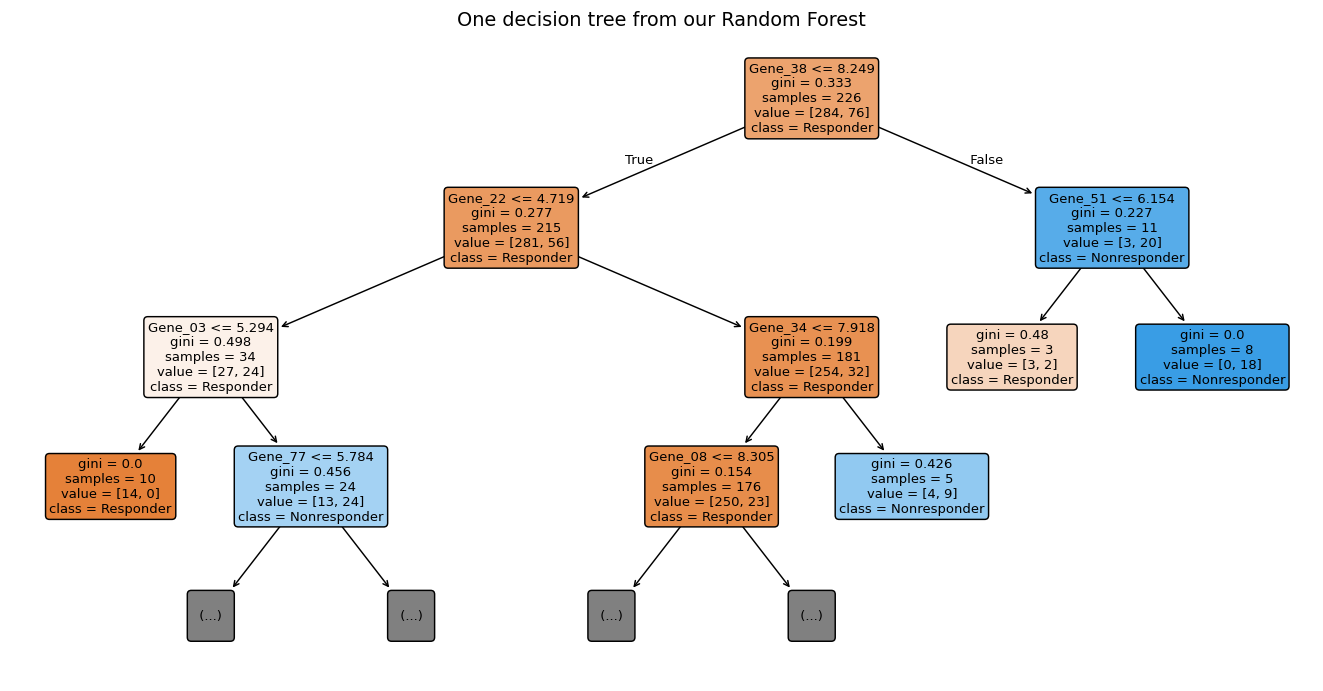

In [15]:
from sklearn.tree import plot_tree

plt.figure(figsize=(16, 8))

plot_tree(
    rf_demo.estimators_[0],
    feature_names=GENES,
    class_names=["Responder", "Nonresponder"],
    max_depth=3,
    filled=True,
    rounded=True,
    fontsize=9
)

plt.title("One decision tree from our Random Forest")
plt.show()

**Predict:** Why might a Random Forest perform better on new samples than a single unpruned decision tree?

**Explain:** Run the cell below and examine the Random Forest feature-importance plot. Which genes contribute most to classification? Does high feature importance demonstrate that these genes cause treatment nonresponse? Why or why not?

**Your response:** Predict: A Random Forest might outperform on new samples because it combines predicitions from multiple decision trees which helps reduce overfitting compared to a single unpruned tree.

Explain: Gene_12 and Gene_06 contribute the most to classification, followed by Gene_27 and Gene_13, since they have the highest feature importance values. However, high feature importance does not mean these genes cause treatment nonresponse. It only shows that the Random Forest uses these genes to help predict treatment response. Other factors could influence both gene expression and treatment response, so we would need additional biological experiments to determine whether these genes actually cause nonresponse.


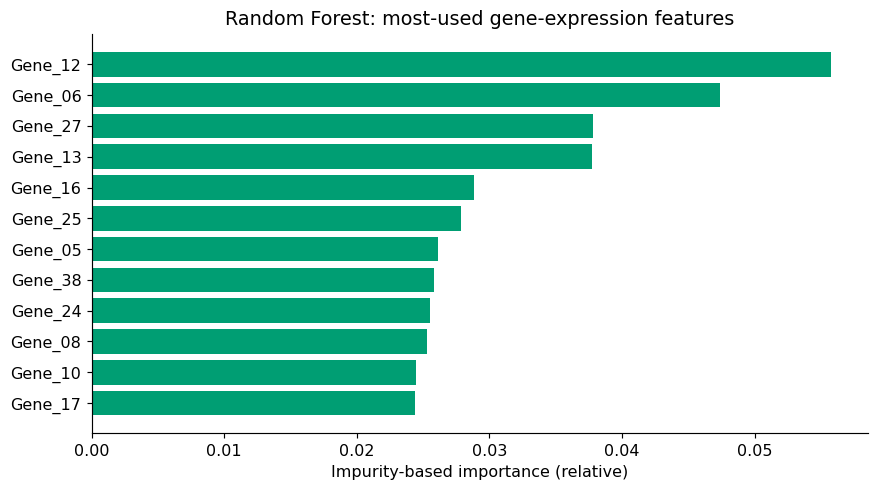

Random Forest training F1: 0.904
Random Forest validation F1: 0.432


In [13]:
rf_demo=RandomForestClassifier(n_estimators=150,max_depth=7,min_samples_leaf=3,
                               random_state=SEED,n_jobs=-1)
rf_demo.fit(X_train,y_train)
important=np.argsort(rf_demo.feature_importances_)[-12:][::-1]
fig,ax=plt.subplots(figsize=(8.5,4.8))
ax.barh([GENES[i] for i in important[::-1]],rf_demo.feature_importances_[important[::-1]],color=GREEN)
ax.set(xlabel='Impurity-based importance (relative)',title='Random Forest: most-used gene-expression features')
finish('05_random_forest_features')
print('Random Forest training F1:',round(f1_score(y_train,rf_demo.predict(X_train)),3))
print('Random Forest validation F1:',round(f1_score(y_val,rf_demo.predict(X_val)),3))